In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

In [2]:


df = pd.read_csv(r"D:\Project_Github\gold assisstant\dataset\datset a gold price\gold_price_2006_2026.csv")
df = df.copy()
df

,date,time,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change
0,2006-05-01,09:30:00,1,11279.04,11950.0,11450.0,11550.0,648.64,37.33,NaN
1,2006-05-02,09:30:00,1,11339.68,12000.0,11500.0,11600.0,656.25,37.61,50.0
2,2006-05-02,11:50:00,2,11385.16,12050.0,11550.0,11650.0,657.05,NaN,50.0
3,2006-05-03,09:30:00,1,11582.24,12250.0,11750.0,11850.0,668.90,37.58,200.0
4,2006-05-03,10:45:00,2,11733.84,12400.0,11900.0,12000.0,675.90,37.61,150.0
...,...,...,...,...,...,...,...,...,...,...
24514,2026-10-13,10:13:00,4,64930.28,67250.0,66250.0,66450.0,4179.00,33.59,50.0
24515,2026-10-13,10:27:00,5,64975.76,67300.0,66300.0,66500.0,4182.00,33.59,50.0
24516,2026-10-13,11:03:00,6,65021.24,67350.0,66350.0,66550.0,4188.00,33.58,50.0
24517,2026-10-13,11:25:00,7,65066.72,67400.0,66400.0,66600.0,4191.00,33.58,50.0


In [3]:
df.columns.tolist()

['date',
 'time',
 'session',
 'ornament_buy',
 'ornament_sell',
 'bar_buy',
 'bar_sell',
 'gold_spot',
 'thb_usd',
 'change']

In [4]:
df.describe()

,session,ornament_buy,ornament_sell,bar_buy,bar_sell,gold_spot,thb_usd,change
count,24519.000000,24519.000000,24519.000000,24519.000000,24519.000000,23971.000000,23723.000000,24518.000000
mean,7.049268,37768.218860,39174.344386,38481.514336,38601.368327,2515.633273,32.942175,2.249368
std,10.067191,20402.077174,21038.698436,20851.638216,20879.547592,1385.302766,1.762650,126.783632
min,1.000000,9854.000000,10500.000000,10000.000000,10100.000000,543.100000,13.420000,-2550.000000
25%,1.000000,19889.920000,20750.000000,20200.000000,20300.000000,1331.500000,31.650000,-50.000000
50%,3.000000,28925.280000,30050.000000,29450.000000,29550.000000,1896.000000,32.750000,0.000000
75%,8.000000,61049.320000,63200.000000,62300.000000,62400.000000,4037.250000,33.870000,50.000000
max,106.000000,80211.560000,82750.000000,81850.000000,81950.000000,33455.000000,38.900000,3700.000000


In [5]:
print(df.head)

<bound method NDFrame.head of              date      time  session  ornament_buy  ornament_sell  bar_buy  \
0      2006-05-01  09:30:00        1      11279.04        11950.0  11450.0   
1      2006-05-02  09:30:00        1      11339.68        12000.0  11500.0   
2      2006-05-02  11:50:00        2      11385.16        12050.0  11550.0   
3      2006-05-03  09:30:00        1      11582.24        12250.0  11750.0   
4      2006-05-03  10:45:00        2      11733.84        12400.0  11900.0   
...           ...       ...      ...           ...            ...      ...   
24514  2026-10-13  10:13:00        4      64930.28        67250.0  66250.0   
24515  2026-10-13  10:27:00        5      64975.76        67300.0  66300.0   
24516  2026-10-13  11:03:00        6      65021.24        67350.0  66350.0   
24517  2026-10-13  11:25:00        7      65066.72        67400.0  66400.0   
24518  2026-10-13  12:09:00        8      65172.84        67500.0  66500.0   

       bar_sell  gold_spot  thb_u

In [6]:
df.dtypes

date              object
time              object
session            int64
ornament_buy     float64
ornament_sell    float64
bar_buy          float64
bar_sell         float64
gold_spot        float64
thb_usd          float64
change           float64
dtype: object

In [7]:
df.isna().sum()

date               0
time               0
session            0
ornament_buy       0
ornament_sell      0
bar_buy            0
bar_sell           0
gold_spot        548
thb_usd          796
change             1
dtype: int64

In [8]:
df.isna().sum()/len(df)*100

date             0.000000
time             0.000000
session          0.000000
ornament_buy     0.000000
ornament_sell    0.000000
bar_buy          0.000000
bar_sell         0.000000
gold_spot        2.235001
thb_usd          3.246462
change           0.004078
dtype: float64

In [9]:
print("จำนวนแถวซ้ำทั้งหมด:", df.duplicated().sum())

จำนวนแถวซ้ำทั้งหมด: 0


In [10]:
df["timestamp"] = pd.to_datetime(df["date"].astype(str)+" "+df["time"].astype(str))
df[["date", "time", "timestamp"]].head()

,date,time,timestamp
0,2006-05-01,09:30:00,2006-05-01 09:30:00
1,2006-05-02,09:30:00,2006-05-02 09:30:00
2,2006-05-02,11:50:00,2006-05-02 11:50:00
3,2006-05-03,09:30:00,2006-05-03 09:30:00
4,2006-05-03,10:45:00,2006-05-03 10:45:00


In [11]:
print("Timestamp ซ้ำ:", df["timestamp"].duplicated().sum())

Timestamp ซ้ำ: 8


In [12]:
duplicate_timestamps = df[
    df["timestamp"].duplicated(keep=False)
].sort_values("timestamp")

duplicate_timestamps[
    [
        "date", "time", "session",
        "bar_buy", "bar_sell",
        "gold_spot", "thb_usd", "change"
    ]
]

,date,time,session,bar_buy,bar_sell,gold_spot,thb_usd,change
126,2006-07-18,14:40:00,1,11750.0,11850.0,652.2,38.18,-400.0
127,2006-07-18,14:40:00,2,11700.0,11800.0,647.8,38.17,-50.0
805,2008-03-06,15:28:00,2,14700.0,14800.0,991.0,31.58,50.0
806,2008-03-06,15:28:00,3,14600.0,14700.0,985.0,31.58,-100.0
957,2008-05-28,15:35:00,4,13700.0,13800.0,897.5,32.27,-50.0
958,2008-05-28,15:35:00,5,13800.0,13900.0,908.1,32.27,100.0
1147,2008-08-30,09:30:00,1,13450.0,13550.0,832.0,34.25,-50.0
1148,2008-08-30,09:30:00,2,14500.0,14600.0,926.2,33.52,1050.0
2034,2009-12-17,10:16:00,2,17700.0,17800.0,1126.0,33.25,-150.0
2035,2009-12-17,10:16:00,3,17800.0,17900.0,1134.0,33.25,100.0


In [13]:
#ดูว่าข้อมูลเรียงตามเวลามั้ย
out_of_order = df["timestamp"].diff() < pd.Timedelta(0)

print("จำนวนครั้งที่เวลาเรียงย้อนกลับ:", out_of_order.sum())


จำนวนครั้งที่เวลาเรียงย้อนกลับ: 0


In [14]:
#ดูว่ามีราคาผิดปกติมั้ย
price_cols = [
    "ornament_buy",
    "ornament_sell",
    "bar_buy",
    "bar_sell",
    "gold_spot",
    "thb_usd"
]

(df[price_cols] <= 0).sum()

ornament_buy     0
ornament_sell    0
bar_buy          0
bar_sell         0
gold_spot        0
thb_usd          0
dtype: int64

In [15]:
#ดูว่าราคาซื้อ > ราคาขายมั้ย

print("bar_buy > bar_sell:",
      (df["bar_buy"] > df["bar_sell"]).sum())

print("ornament_buy > ornament_sell:",
      (df["ornament_buy"] > df["ornament_sell"]).sum())

bar_buy > bar_sell: 0
ornament_buy > ornament_sell: 0


In [16]:
#ดูข้อมูลแต่ละ session

print("session ที่หายไป :", df["session"].isna().sum())
print("session น้อยสุด :", df["session"].min())
print("session มากสุด :", df["session"].max())

print("จำนวนแถวในแต่ละ session:")
print(df["session"].value_counts().sort_index())

session ที่หายไป : 0
session น้อยสุด : 1
session มากสุด : 106
จำนวนแถวในแต่ละ session:
session
1      6261
2      4039
3      2810
4      1910
5      1324
       ... 
102       2
103       1
104       1
105       1
106       1
Name: count, Length: 106, dtype: int64


In [17]:
# สร้างข้อมูลรายวันและรายเดือน

daily_sessions = (
    df.groupby("date")
      .agg(
          n_rows=("session", "size"),
          n_sessions=("session", "nunique"),
          max_session=("session", "max")
      )
      .reset_index()
)

daily_sessions["date"] = pd.to_datetime(daily_sessions["date"])
daily_sessions["month"] = daily_sessions["date"].dt.to_period("M")

daily_sessions.head()

,date,n_rows,n_sessions,max_session,month
0,2006-05-01,1,1,1,2006-05
1,2006-05-02,2,2,2,2006-05
2,2006-05-03,4,4,4,2006-05
3,2006-05-04,1,1,1,2006-05
4,2006-05-06,1,1,1,2006-05


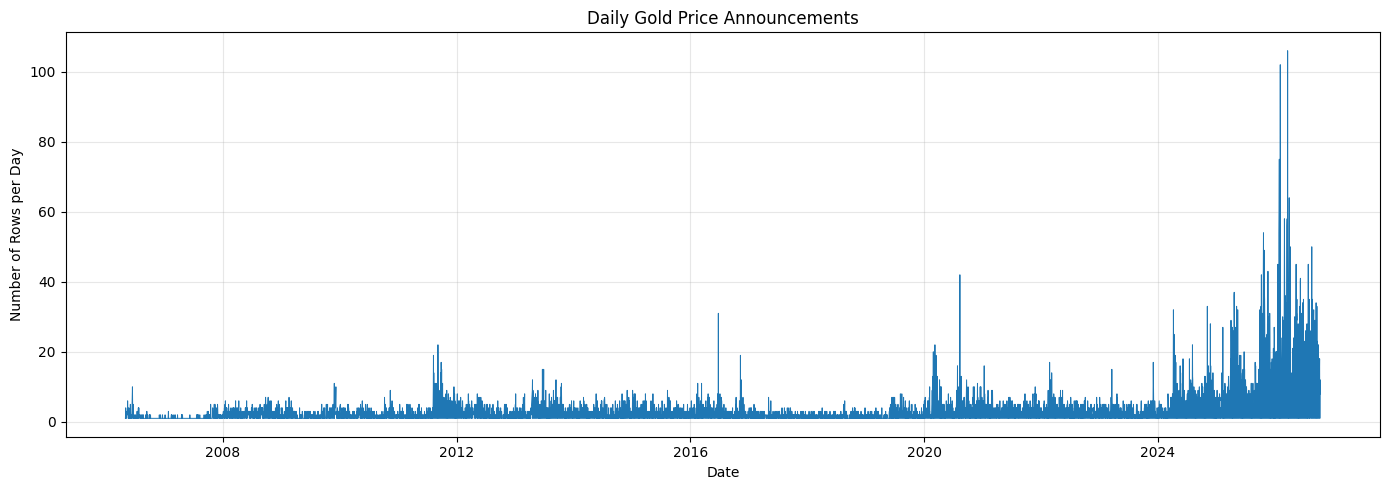

In [18]:
plt.figure(figsize=(14, 5))

plt.plot(
    daily_sessions["date"],
    daily_sessions["n_rows"],
    linewidth=0.7
)

plt.title("Daily Gold Price Announcements")
plt.xlabel("Date")
plt.ylabel("Number of Rows per Day")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
#สถิติรายเดือน

monthly_summary = (
    daily_sessions.groupby("month")
    .agg(
        days=("date", "nunique"),
        avg_rows=("n_rows", "mean"),
        median_rows=("n_rows", "median"),
        max_rows=("n_rows", "max"),
        max_session=("max_session", "max")
    )
    .round(2)
)

monthly_summary.tail(12)

,days,avg_rows,median_rows,max_rows,max_session
month,,,,,
2025-11,25,17.20,16.0,43,43
2025-12,27,12.41,12.0,31,31
2026-01,27,20.30,17.0,75,75
2026-02,24,25.33,17.0,102,102
2026-03,26,30.85,30.0,106,106
2026-04,26,18.88,14.0,64,64
2026-05,26,20.50,21.5,45,45
2026-06,26,21.42,21.0,41,41
2026-07,28,15.89,16.0,45,45


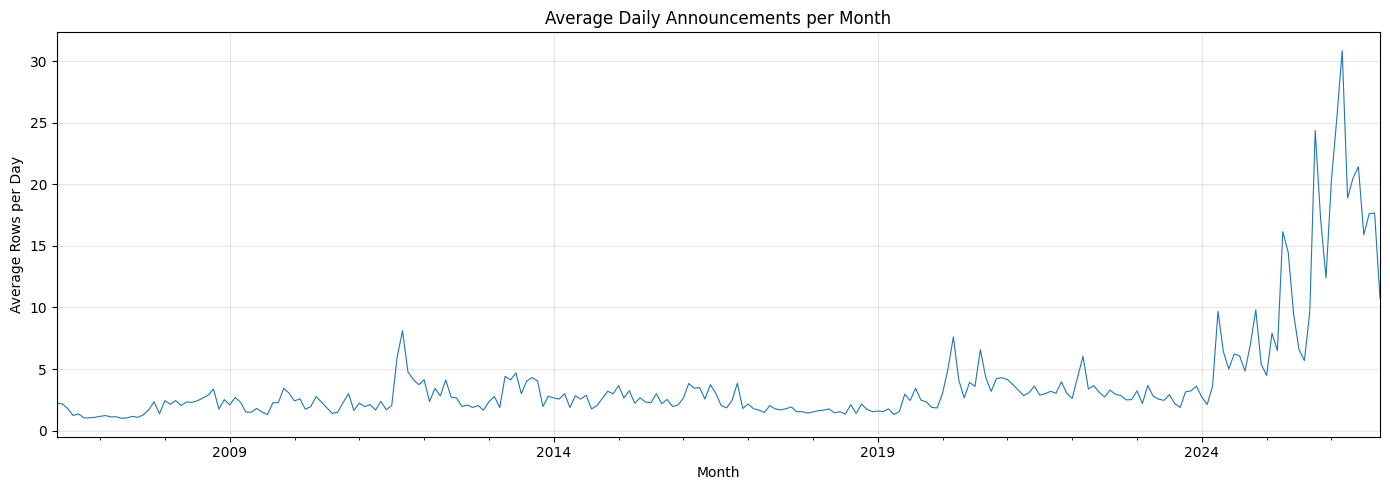

In [20]:
monthly_rows = (
    daily_sessions.groupby("month")["n_rows"]
    .mean()
)

plt.figure(figsize=(14, 5))

monthly_rows.plot(linewidth=0.8)

plt.title("Average Daily Announcements per Month")
plt.xlabel("Month")
plt.ylabel("Average Rows per Day")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [21]:
# หา Outlier ภายในแต่ละเดือนด้วย

def find_monthly_outliers(group):
    q1 = group["n_rows"].quantile(0.25)
    q3 = group["n_rows"].quantile(0.75)
    iqr = q3 - q1

    upper_bound = q3 + 1.5 * iqr
    lower_bound = max(0, q1 - 1.5 * iqr)

    result = group.copy()
    result["q1"] = q1
    result["q3"] = q3
    result["lower_bound"] = lower_bound
    result["upper_bound"] = upper_bound

    result["is_outlier"] = (
        (result["n_rows"] < lower_bound)
        | (result["n_rows"] > upper_bound)
    )

    return result

daily_outliers = (
    daily_sessions.groupby("month", group_keys=False)
    .apply(find_monthly_outliers)
    .reset_index(drop=True)
)

outlier_days = (
    daily_outliers[daily_outliers["is_outlier"]]
    .sort_values(["month", "n_rows"], ascending=[True, False])
)

outlier_days[
    ["date", "month", "n_rows", "n_sessions", "max_session",
     "lower_bound", "upper_bound"]
].head(30)

C:\Users\User\AppData\Local\Temp\ipykernel_7596\1420841631.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(find_monthly_outliers)


,date,month,n_rows,n_sessions,max_session,lower_bound,upper_bound
34,2006-06-14,2006-06,10,10,10,0.0,3.5
25,2006-06-01,2006-06,5,5,5,0.0,3.5
35,2006-06-15,2006-06,5,5,5,0.0,3.5
38,2006-06-19,2006-06,5,5,5,0.0,3.5
65,2006-07-21,2006-07,4,4,4,0.0,3.5
67,2006-07-24,2006-07,4,4,4,0.0,3.5
74,2006-08-01,2006-08,2,2,2,1.0,1.0
75,2006-08-02,2006-08,2,2,2,1.0,1.0
76,2006-08-03,2006-08,2,2,2,1.0,1.0
82,2006-08-10,2006-08,2,2,2,1.0,1.0


In [22]:
outlier_days.head(10)

,date,n_rows,n_sessions,max_session,month,q1,q3,lower_bound,upper_bound,is_outlier
34,2006-06-14,10,10,10,2006-06,1.0,2.0,0.0,3.5,True
25,2006-06-01,5,5,5,2006-06,1.0,2.0,0.0,3.5,True
35,2006-06-15,5,5,5,2006-06,1.0,2.0,0.0,3.5,True
38,2006-06-19,5,5,5,2006-06,1.0,2.0,0.0,3.5,True
65,2006-07-21,4,4,4,2006-07,1.0,2.0,0.0,3.5,True
67,2006-07-24,4,4,4,2006-07,1.0,2.0,0.0,3.5,True
74,2006-08-01,2,2,2,2006-08,1.0,1.0,1.0,1.0,True
75,2006-08-02,2,2,2,2006-08,1.0,1.0,1.0,1.0,True
76,2006-08-03,2,2,2,2006-08,1.0,1.0,1.0,1.0,True
82,2006-08-10,2,2,2,2006-08,1.0,1.0,1.0,1.0,True


In [23]:
outlier_days.tail(20)

,date,n_rows,n_sessions,max_session,month,q1,q3,lower_bound,upper_bound,is_outlier
5977,2025-12-01,31,31,31,2025-12,7.50,16.50,0.00,30.000,True
6029,2026-01-30,75,75,75,2026-01,9.00,21.00,0.00,39.000,True
6028,2026-01-29,60,60,60,2026-01,9.00,21.00,0.00,39.000,True
6027,2026-01-28,54,54,54,2026-01,9.00,21.00,0.00,39.000,True
6021,2026-01-21,45,45,45,2026-01,9.00,21.00,0.00,39.000,True
6034,2026-02-05,102,102,102,2026-02,13.50,29.25,0.00,52.875,True
6031,2026-02-02,69,69,69,2026-02,13.50,29.25,0.00,52.875,True
6032,2026-02-03,63,63,63,2026-02,13.50,29.25,0.00,52.875,True
6035,2026-02-06,60,60,60,2026-02,13.50,29.25,0.00,52.875,True
6073,2026-03-23,106,106,106,2026-03,16.00,40.50,0.00,77.250,True


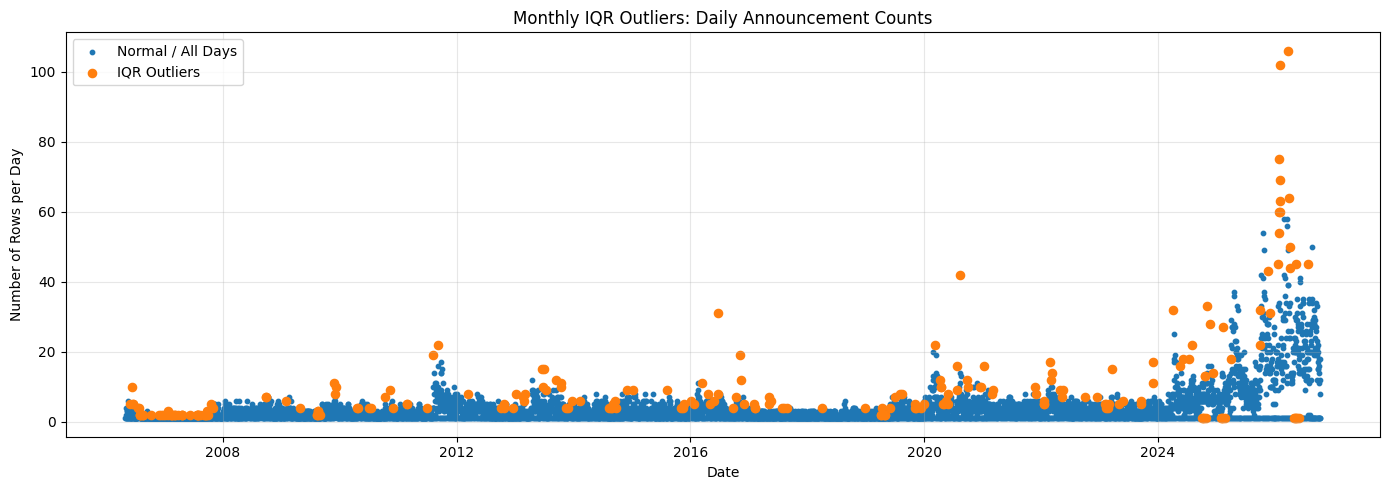

In [24]:
outlier_days = daily_outliers[
    daily_outliers["is_outlier"]
]

plt.figure(figsize=(14, 5))

plt.scatter(
    daily_outliers["date"],
    daily_outliers["n_rows"],
    s=10,
    label="Normal / All Days"
)

plt.scatter(
    outlier_days["date"],
    outlier_days["n_rows"],
    s=35,
    label="IQR Outliers"
)

plt.title("Monthly IQR Outliers: Daily Announcement Counts")
plt.xlabel("Date")
plt.ylabel("Number of Rows per Day")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## จะเห็นว่าหลังปี 2025 มีประกาศเพิ่มเยอะ น่าจรวจสอบต่อ

In [25]:
daily_sessions["period"] = daily_sessions["date"].dt.year.map(
    lambda year: "Before 2025" if year < 2025 else "2025 onwards"
)

period_summary = (
    daily_sessions.groupby("period")["n_rows"]
    .agg(
        days="count",
        mean="mean",
        median="median",
        min="min",
        max="max",
        std="std"
    )
    .round(2)
)

period_summary

,days,mean,median,min,max,std
period,,,,,,
2025 onwards,571,15.30,13.0,1,106,13.81
Before 2025,5690,2.77,2.0,1,42,2.48


In [26]:
#หาว่าปีไหนเริ่มเพิ่มเยอะ
daily_sessions["year"] = daily_sessions["date"].dt.year

yearly_summary = (
    daily_sessions.groupby("year")["n_rows"]
    .agg(
        days="count",
        mean="mean",
        median="median",
        max="max"
    )
    .round(2)
)

yearly_summary

,days,mean,median,max
year,,,,
2006,201,1.49,1.0,10
2007,299,1.30,1.0,5
2008,298,2.46,2.0,7
2009,297,2.15,2.0,11
2010,299,2.11,2.0,9
2011,301,3.46,2.0,22
2012,297,2.64,2.0,8
2013,299,3.35,3.0,15
2014,300,2.58,2.0,9


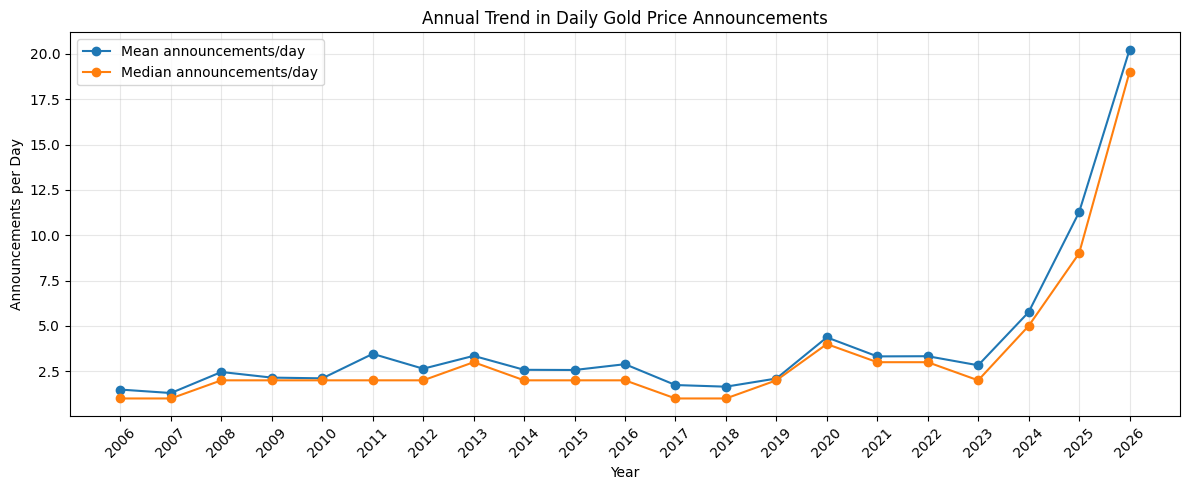

In [27]:
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_summary.index,
    yearly_summary["mean"],
    marker="o",
    label="Mean announcements/day"
)

plt.plot(
    yearly_summary.index,
    yearly_summary["median"],
    marker="o",
    label="Median announcements/day"
)

plt.title("Annual Trend in Daily Gold Price Announcements")
plt.xlabel("Year")
plt.ylabel("Announcements per Day")
plt.xticks(yearly_summary.index, rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
#ดูปีที่ประกาศเพิ่ม
monthly_summary = (
    daily_sessions
    .assign(month=daily_sessions["date"].dt.to_period("M"))
    .groupby("month")["n_rows"]
    .agg(["count", "mean", "median", "max"])
    .round(2)
)

monthly_summary.loc["2025-01":"2026-10"]

,count,mean,median,max
month,,,,
2025-01,27,4.48,5.0,9
2025-02,24,7.92,7.5,27
2025-03,26,6.50,6.0,18
2025-04,26,16.15,15.0,37
2025-05,27,14.48,15.0,33
2025-06,26,9.50,10.0,20
2025-07,27,6.59,7.0,12
2025-08,26,5.69,5.5,11
2025-09,26,9.65,9.0,32


In [29]:
monthly_check = (
    df.assign(month=df["timestamp"].dt.to_period("M"))
      .groupby("month")
      .agg(
          n_rows=("timestamp", "size"),
          unique_timestamps=("timestamp", "nunique"),
          unique_dates=("date", "nunique")
      )
)

monthly_check.loc["2024-01":"2026-10"]

,n_rows,unique_timestamps,unique_dates
month,,,
2024-01,74,74,27
2024-02,53,53,25
2024-03,94,94,26
2024-04,252,252,26
2024-05,173,173,27
2024-06,125,125,25
2024-07,168,168,27
2024-08,164,164,27
2024-09,121,121,25


In [30]:
df = df.sort_values("timestamp").copy()

# ตรวจว่าราคาทองแท่งเปลี่ยนจากแถวก่อนหน้าในวันเดียวกันหรือไม่
prev_buy = df.groupby("date")["bar_buy"].shift()
prev_sell = df.groupby("date")["bar_sell"].shift()

df["price_changed"] = (
    df["bar_buy"].ne(prev_buy) |
    df["bar_sell"].ne(prev_sell)
)

# สรุปผลรายเดือน
monthly_price_changes = (
    df.assign(month=df["timestamp"].dt.to_period("M"))
      .groupby("month")
      .agg(
          n_rows=("timestamp", "size"),
          price_change_rows=("price_changed", "sum")
      )
)

monthly_price_changes["change_ratio"] = (
    monthly_price_changes["price_change_rows"]
    / monthly_price_changes["n_rows"]
).round(3)

monthly_price_changes.loc["2024-01":"2026-10"]

,n_rows,price_change_rows,change_ratio
month,,,
2024-01,74,74,1.0
2024-02,53,53,1.0
2024-03,94,94,1.0
2024-04,252,252,1.0
2024-05,173,173,1.0
2024-06,125,125,1.0
2024-07,168,168,1.0
2024-08,164,164,1.0
2024-09,121,121,1.0


In [31]:
df = df.sort_values("timestamp").copy()

g = df.groupby("date")

prev_buy = g["bar_buy"].shift()
prev_sell = g["bar_sell"].shift()

valid_pairs = (
    df["bar_buy"].notna()
    & prev_buy.notna()
    & df["bar_sell"].notna()
    & prev_sell.notna()
)

df["price_changed"] = (
    valid_pairs
    & (
        df["bar_buy"].ne(prev_buy)
        | df["bar_sell"].ne(prev_sell)
    )
)

df["valid_price_pair"] = valid_pairs

monthly_price_changes = (
    df.assign(month=df["timestamp"].dt.to_period("M"))
      .groupby("month")
      .agg(
          n_rows=("timestamp", "size"),
          valid_pairs=("valid_price_pair", "sum"),
          price_change_rows=("price_changed", "sum")
      )
)

monthly_price_changes["change_ratio"] = (
    monthly_price_changes["price_change_rows"]
    / monthly_price_changes["valid_pairs"].replace(0, float("nan"))
).round(3)

monthly_price_changes.loc["2024-01":"2026-10"]

,n_rows,valid_pairs,price_change_rows,change_ratio
month,,,,
2024-01,74,47,47,1.0
2024-02,53,28,28,1.0
2024-03,94,68,68,1.0
2024-04,252,226,226,1.0
2024-05,173,146,146,1.0
2024-06,125,100,100,1.0
2024-07,168,141,141,1.0
2024-08,164,137,137,1.0
2024-09,121,96,96,1.0


In [32]:
# ดูตัวอย่าง 20 แถวแรกของวันที่มีข้อมูลมากในเดือนมีนาคม 2026
sample_day = (
    df.loc[df["date"].astype(str) == "2026-03-23"]
      .sort_values("timestamp")
      [["timestamp", "session", "bar_buy", "bar_sell", "change"]]
)

sample_day.head(20)

,timestamp,session,bar_buy,bar_sell,change
20962,2026-03-23 09:00:00,1,68400.0,68600.0,-1850.0
20963,2026-03-23 09:03:00,2,68800.0,69000.0,400.0
20964,2026-03-23 09:12:00,3,66800.0,67000.0,-2000.0
20965,2026-03-23 09:13:00,4,66700.0,66900.0,-100.0
20966,2026-03-23 09:15:00,5,68600.0,68800.0,1900.0
20967,2026-03-23 09:18:00,6,68800.0,69000.0,200.0
20968,2026-03-23 09:20:00,7,68600.0,68800.0,-200.0
20969,2026-03-23 09:21:00,8,68700.0,68900.0,100.0
20970,2026-03-23 09:32:00,9,68600.0,68800.0,-100.0
20971,2026-03-23 09:34:00,10,68500.0,68700.0,-100.0


In [33]:

# เรียงข้อมูลตามเวลา
df = df.sort_values("timestamp").copy()

# ราคาก่อนหน้าภายในวันเดียวกัน
df["prev_bar_buy"] = df.groupby("date")["bar_buy"].shift()

# คำนวณขนาดการเปลี่ยนแปลง
df["bar_buy_change"] = df["bar_buy"] - df["prev_bar_buy"]

# เลือกเฉพาะคู่ราคาที่มีข้อมูลครบ
valid_changes = df["bar_buy_change"].dropna()

print("จำนวนคู่ราคาที่ตรวจสอบได้:", len(valid_changes))
print("สัดส่วนที่ราคาเปลี่ยน:", (valid_changes != 0).mean().round(4))
print("สัดส่วนราคาขึ้น:", (valid_changes > 0).mean().round(4))
print("สัดส่วนราคาลง:", (valid_changes < 0).mean().round(4))

print("\nขนาดการเปลี่ยนแปลง (บาท)")
print(valid_changes.abs().describe().round(2))


จำนวนคู่ราคาที่ตรวจสอบได้: 18258
สัดส่วนที่ราคาเปลี่ยน: 0.9997
สัดส่วนราคาขึ้น: 0.5016
สัดส่วนราคาลง: 0.4981

ขนาดการเปลี่ยนแปลง (บาท)
count    18258.00
mean        60.01
std         42.79
min          0.00
25%         50.00
50%         50.00
75%         50.00
max       2000.00
Name: bar_buy_change, dtype: float64


# max       2000.00 น่าสงสัย เลยควรตรวจต่อ

In [34]:

# แสดง 15 รายการที่ราคาซื้อทองแท่งเปลี่ยนแปลงมากที่สุด
cols = [
    "timestamp",
    "session",
    "prev_bar_buy",
    "bar_buy",
    "bar_buy_change",
    "bar_sell",
    "change",
]

largest_moves = (
    df.loc[df["bar_buy_change"].notna(), cols]
      .assign(abs_change=lambda x: x["bar_buy_change"].abs())
      .sort_values("abs_change", ascending=False)
      .head(15)
)

largest_moves


,timestamp,session,prev_bar_buy,bar_buy,bar_buy_change,bar_sell,change,abs_change
20964,2026-03-23 09:12:00,3,68800.0,66800.0,-2000.0,67000.0,-2000.0,2000.0
20966,2026-03-23 09:15:00,5,66700.0,68600.0,1900.0,68800.0,1900.0,1900.0
1231,2008-10-03 10:20:00,3,12400.0,13600.0,1200.0,13700.0,1200.0,1200.0
1233,2008-10-03 11:45:00,5,12450.0,13650.0,1200.0,13750.0,1200.0,1200.0
1230,2008-10-03 09:33:00,2,13550.0,12400.0,-1150.0,12500.0,-1150.0,1150.0
1232,2008-10-03 11:27:00,4,13600.0,12450.0,-1150.0,12550.0,-1150.0,1150.0
1149,2008-08-30 14:40:00,3,13450.0,14550.0,1100.0,14650.0,50.0,1100.0
1147,2008-08-30 09:30:00,1,14500.0,13450.0,-1050.0,13550.0,-50.0,1050.0
19792,2026-01-30 09:15:00,2,78850.0,77900.0,-950.0,78000.0,-950.0,950.0
19893,2026-02-02 12:54:00,27,69800.0,69000.0,-800.0,69200.0,-800.0,800.0


In [35]:

# ตรวจลำดับประกาศราคาของวันที่ 23 มีนาคม 2026
sample = (
    df.loc[df["timestamp"].dt.date == pd.Timestamp("2026-03-23").date(),
           ["timestamp", "session", "bar_buy", "bar_sell", "change"]]
      .sort_values("timestamp")
      .copy()
)

sample["prev_bar_buy"] = sample["bar_buy"].shift(1)
sample["bar_buy_change"] = sample["bar_buy"] - sample["prev_bar_buy"]

sample[
    ["timestamp", "session", "prev_bar_buy", "bar_buy",
     "bar_buy_change", "bar_sell", "change"]
].head(15)


,timestamp,session,prev_bar_buy,bar_buy,bar_buy_change,bar_sell,change
20962,2026-03-23 09:00:00,1,NaN,68400.0,NaN,68600.0,-1850.0
20963,2026-03-23 09:03:00,2,68400.0,68800.0,400.0,69000.0,400.0
20964,2026-03-23 09:12:00,3,68800.0,66800.0,-2000.0,67000.0,-2000.0
20965,2026-03-23 09:13:00,4,66800.0,66700.0,-100.0,66900.0,-100.0
20966,2026-03-23 09:15:00,5,66700.0,68600.0,1900.0,68800.0,1900.0
20967,2026-03-23 09:18:00,6,68600.0,68800.0,200.0,69000.0,200.0
20968,2026-03-23 09:20:00,7,68800.0,68600.0,-200.0,68800.0,-200.0
20969,2026-03-23 09:21:00,8,68600.0,68700.0,100.0,68900.0,100.0
20970,2026-03-23 09:32:00,9,68700.0,68600.0,-100.0,68800.0,-100.0
20971,2026-03-23 09:34:00,10,68600.0,68500.0,-100.0,68700.0,-100.0


In [36]:
#ตรวจความสอดคล้องของ change ทั้ง dataset
df = df.sort_values("timestamp").copy()

# ผลต่างราคาซื้อทองแท่งจากประกาศก่อนหน้าทั้ง dataset
df["prev_bar_buy_all"] = df["bar_buy"].shift(1)

df["bar_buy_change_all"] = (
    df["bar_buy"] - df["prev_bar_buy_all"]
)

# เปรียบเทียบกับคอลัมน์ change เมื่อทั้งสองค่ามีข้อมูล
valid = df["change"].notna() & df["bar_buy_change_all"].notna()

comparison = df.loc[valid].copy()
comparison["match"] = (
    comparison["change"] == comparison["bar_buy_change_all"]
)

print("จำนวนคู่ที่เปรียบเทียบได้:", len(comparison))
print("จำนวนที่ตรงกัน:", comparison["match"].sum())
print("สัดส่วนที่ตรงกัน:", round(comparison["match"].mean(), 4))

print("\nตัวอย่างรายการที่ไม่ตรงกัน:")
comparison.loc[
    ~comparison["match"],
    ["timestamp", "session", "bar_buy", "bar_buy_change_all", "change"]
].head(10)


จำนวนคู่ที่เปรียบเทียบได้: 24518
จำนวนที่ตรงกัน: 24514
สัดส่วนที่ตรงกัน: 0.9998

ตัวอย่างรายการที่ไม่ตรงกัน:


,timestamp,session,bar_buy,bar_buy_change_all,change
10020,2020-03-25 10:29:00,1,24500.0,100.0,300.0
10037,2020-03-28 09:31:00,1,24750.0,250.0,150.0
10219,2020-06-01 09:22:00,1,26000.0,150.0,50.0
19867,2026-02-02 09:45:00,1,72350.0,-1750.0,-1650.0


In [37]:

# index ของแถวที่ change ไม่ตรงกับผลต่าง bar_buy
mismatch_idx = comparison.index[~comparison["match"]]

# แสดงแถวก่อนหน้า แถวที่พบปัญหา และแถวถัดไป
context_rows = []

for idx in mismatch_idx:
    pos = df.index.get_loc(idx)

    start = max(0, pos - 1)
    end = min(len(df), pos + 2)

    context_rows.append(
        df.iloc[start:end][
            ["timestamp", "session", "bar_buy", "change"]
        ]
    )

mismatch_context = pd.concat(context_rows).drop_duplicates()
mismatch_context


,timestamp,session,bar_buy,change
10019,2020-03-24 16:38:00,13,24400.0,50.0
10020,2020-03-25 10:29:00,1,24500.0,300.0
10021,2020-03-25 10:44:00,2,24450.0,-50.0
10036,2020-03-27 16:51:00,5,24500.0,50.0
10037,2020-03-28 09:31:00,1,24750.0,150.0
10038,2020-03-30 09:30:00,1,24700.0,-50.0
10218,2020-05-30 09:18:00,1,25850.0,50.0
10219,2020-06-01 09:22:00,1,26000.0,50.0
10220,2020-06-01 09:35:00,2,26050.0,50.0
19866,2026-01-31 09:23:00,1,74100.0,-1200.0


In [38]:

df = df.sort_values("timestamp").copy()

df["prev_bar_buy_all"] = df["bar_buy"].shift(1)
df["bar_buy_change_all"] = df["bar_buy"] - df["prev_bar_buy_all"]

df["is_first_session"] = df["session"].eq(1)

valid = df["change"].notna() & df["bar_buy_change_all"].notna()

comparison = df.loc[valid].copy()
comparison["match"] = (
    comparison["change"] == comparison["bar_buy_change_all"]
)

print("ความสอดคล้องของ change แยกตาม session")

comparison.groupby("is_first_session").agg(
    n=("match", "size"),
    matches=("match", "sum"),
    match_ratio=("match", "mean")
).round(4)


ความสอดคล้องของ change แยกตาม session


,n,matches,match_ratio
is_first_session,,,
False,18258,18254,0.9998
True,6260,6255,0.9992


มีทั้งหมด 9 คู่ที่ไม่ตรงกัน จาก 24,518 คู่ที่เปรียบเทียบได้ โดย 5 คู่เป็นประกาศแรกของวัน และอีก 4 คู่เป็นประกาศอื่น

In [39]:

# แถวที่ change ไม่ตรงกับผลต่าง bar_buy
mismatches = comparison.loc[~comparison["match"]].copy()

mismatches["difference_between_changes"] = (
    mismatches["change"] - mismatches["bar_buy_change_all"]
)

mismatches[
    [
        "timestamp",
        "session",
        "bar_buy",
        "prev_bar_buy_all",
        "bar_buy_change_all",
        "change",
        "difference_between_changes",
    ]
].sort_values("timestamp")


,timestamp,session,bar_buy,prev_bar_buy_all,bar_buy_change_all,change,difference_between_changes
1148,2008-08-30 09:30:00,2,14500.0,13500.0,1000.0,1050.0,50.0
1147,2008-08-30 09:30:00,1,13450.0,14500.0,-1050.0,-50.0,1000.0
1149,2008-08-30 14:40:00,3,14550.0,13450.0,1100.0,50.0,-1050.0
2058,2009-12-30 15:42:00,4,17250.0,17300.0,-50.0,0.0,50.0
2057,2009-12-30 15:42:00,3,17250.0,17250.0,0.0,-50.0,-50.0
10020,2020-03-25 10:29:00,1,24500.0,24400.0,100.0,300.0,200.0
10037,2020-03-28 09:31:00,1,24750.0,24500.0,250.0,150.0,-100.0
10219,2020-06-01 09:22:00,1,26000.0,25850.0,150.0,50.0,-100.0
19867,2026-02-02 09:45:00,1,72350.0,74100.0,-1750.0,-1650.0,100.0


จากการที่นำไปตรวจสอบกับข่าวพบว่า แบ่ง 9 แถวที่ไม่ตรงกันได้เป็น 3 กลุ่มเบื้องต้น:
- 5 แถวในปี 2008 และ 2009: มี timestamp ซ้ำและลำดับประกาศที่ต้องตรวจสอบ ข้อมูลเดือนสิงหาคม 2008 มีความผิดปกติของ Gold Spot ที่เห็นได้ชัดเมื่อเทียบกับประวัติราคาทองโลก
- 3 แถวในปี 2020: ตรงกับช่วงที่สมาคมค้าทองคำเปลี่ยนมาตรการกำหนดส่วนต่างซื้อ–ขายเนื่องจากวิกฤต COVID-19
- 1 แถวในปี 2026: เกิดในช่วงทองคำโลกเทขายอย่างรุนแรง แต่ความคลาดเคลื่อนของข้อมูลยังต้องตรวจแยกจากเหตุการณ์ตลาด

In [40]:
# เรียงด้วยเวลาและหมายเลขประกาศ
df_ordered = df.sort_values(
    ["timestamp", "session"]
).copy()

# คำนวณผลต่างราคาจากแถวก่อนหน้า
df_ordered["prev_bar_buy_ordered"] = (
    df_ordered["bar_buy"].shift(1)
)

df_ordered["bar_buy_change_ordered"] = (
    df_ordered["bar_buy"]
    - df_ordered["prev_bar_buy_ordered"]
)

# เปรียบเทียบกับ change เดิม
valid = (
    df_ordered["change"].notna()
    & df_ordered["bar_buy_change_ordered"].notna()
)

check = df_ordered.loc[valid].copy()

check["match"] = (
    check["change"]
    == check["bar_buy_change_ordered"]
)

print("จำนวนคู่ที่ตรวจสอบได้:", len(check))
print("จำนวนที่ตรงกัน:", check["match"].sum())
print("จำนวนที่ไม่ตรงกัน:", (~check["match"]).sum())

จำนวนคู่ที่ตรวจสอบได้: 24518
จำนวนที่ตรงกัน: 24514
จำนวนที่ไม่ตรงกัน: 4


In [41]:

# เลือกเฉพาะแถวที่ change ไม่ตรงกับผลต่าง bar_buy
remaining_mismatches = check.loc[~check["match"]].copy()

remaining_mismatches["difference"] = (
    remaining_mismatches["change"]
    - remaining_mismatches["bar_buy_change_ordered"]
)

display(
    remaining_mismatches[
        [
            "timestamp",
            "session",
            "prev_bar_buy_ordered",
            "bar_buy",
            "bar_buy_change_ordered",
            "change",
            "difference",
        ]
    ].sort_values("timestamp")
)


,timestamp,session,prev_bar_buy_ordered,bar_buy,bar_buy_change_ordered,change,difference
10020,2020-03-25 10:29:00,1,24400.0,24500.0,100.0,300.0,200.0
10037,2020-03-28 09:31:00,1,24500.0,24750.0,250.0,150.0,-100.0
10219,2020-06-01 09:22:00,1,25850.0,26000.0,150.0,50.0,-100.0
19867,2026-02-02 09:45:00,1,74100.0,72350.0,-1750.0,-1650.0,100.0


In [42]:

# เรียงตามเวลาและหมายเลขประกาศ
df_ordered = df.sort_values(
    ["timestamp", "session"]
).copy()

# ราคาขายทองแท่งจากประกาศก่อนหน้า
df_ordered["prev_bar_sell"] = (
    df_ordered["bar_sell"].shift(1)
)

# ผลต่างราคาขายทองแท่ง
df_ordered["bar_sell_change"] = (
    df_ordered["bar_sell"]
    - df_ordered["prev_bar_sell"]
)

valid_sell = (
    df_ordered["change"].notna()
    & df_ordered["bar_sell_change"].notna()
)

sell_check = df_ordered.loc[valid_sell].copy()

sell_check["match_sell"] = (
    sell_check["change"]
    == sell_check["bar_sell_change"]
)

print("จำนวนคู่ที่เปรียบเทียบได้:", len(sell_check))
print("จำนวนที่ตรงกัน:", sell_check["match_sell"].sum())
print(
    "อัตราตรงกัน:",
    round(sell_check["match_sell"].mean(), 4)
)

print("\nรายการที่ยังไม่ตรงกัน:")
display(
    sell_check.loc[
        ~sell_check["match_sell"],
        [
            "timestamp", "session", "bar_sell",
            "prev_bar_sell", "bar_sell_change", "change"
        ]
    ].head(10)
)


จำนวนคู่ที่เปรียบเทียบได้: 24518
จำนวนที่ตรงกัน: 24518
อัตราตรงกัน: 1.0

รายการที่ยังไม่ตรงกัน:


,timestamp,session,bar_sell,prev_bar_sell,bar_sell_change,change


ตอนแรกเทียบ change กับผลต่างของ bar_buy ซึ่งเป็นราคาซื้อทองแท่ง จึงพบว่าไม่ตรงกัน 4 แถวจาก 24,518 คู่ แต่เมื่อเปลี่ยนไปเทียบกับผลต่างของ bar_sell ซึ่งเป็นราคาขายทองแท่ง กลับตรงกันครบ 24,518 คู่ หรือ 100%

In [43]:

# ใช้ข้อมูลที่เรียงตามเวลาและ session แล้ว
df_ordered = df.sort_values(
    ["timestamp", "session"]
).copy()

# คำนวณผลต่าง bar_sell ใหม่เพื่อใช้ตรวจสอบ
df_ordered["bar_sell_change_recomputed"] = (
    df_ordered["bar_sell"].diff()
)

df_ordered["abs_bar_sell_change"] = (
    df_ordered["bar_sell_change_recomputed"].abs()
)

# แสดงการเปลี่ยนแปลงขนาดใหญ่ที่สุด 15 รายการ
largest_moves = (
    df_ordered.dropna(subset=["bar_sell_change_recomputed"])
    .nlargest(15, "abs_bar_sell_change")
    [[
        "timestamp",
        "session",
        "bar_sell",
        "bar_sell_change_recomputed",
        "change",
        "abs_bar_sell_change"
    ]]
)

largest_moves


,timestamp,session,bar_sell,bar_sell_change_recomputed,change,abs_bar_sell_change
19731,2026-01-29 09:17:00,1,81400.0,3700.0,3700.0,3700.0
19791,2026-01-30 09:07:00,1,78950.0,-2550.0,-2550.0,2550.0
18251,2025-10-22 09:07:00,1,63750.0,-2500.0,-2500.0,2500.0
21117,2026-03-25 09:02:00,1,70700.0,2400.0,2400.0,2400.0
4714,2013-04-17 09:30:00,1,19000.0,-2350.0,-2350.0,2350.0
19999,2026-02-04 09:08:00,1,75700.0,2100.0,2100.0,2100.0
20964,2026-03-23 09:12:00,3,67000.0,-2000.0,-2000.0,2000.0
20961,2026-03-21 09:00:00,1,70450.0,-1900.0,-1900.0,1900.0
20966,2026-03-23 09:15:00,5,68800.0,1900.0,1900.0,1900.0
22436,2026-06-10 09:02:00,1,65500.0,-1900.0,-1900.0,1900.0


In [44]:
change_summary = (
    df_ordered["bar_sell_change_recomputed"]
    .abs()
    .describe(percentiles=[0.90, 0.95, 0.99, 0.995])
)

change_summary

count    24518.000000
mean        74.237295
std        102.799554
min          0.000000
50%         50.000000
90%        100.000000
95%        200.000000
99%        450.000000
99.5%      650.000000
max       3700.000000
Name: bar_sell_change_recomputed, dtype: float64

การเปลี่ยนแปลงราคาส่วนใหญ่มีขนาดเล็ก แต่มีบางช่วงที่เปลี่ยนแปลงรุนแรงมากเมื่อเทียบกับข้อมูลปกติ

In [45]:
large_moves = df_ordered.loc[
    df_ordered["bar_sell_change_recomputed"].abs() >= 500,
    [
        "timestamp",
        "session",
        "bar_sell",
        "bar_sell_change_recomputed",
        "change"
    ]
].copy()

large_moves["direction"] = large_moves[
    "bar_sell_change_recomputed"
].apply(lambda x: "ขึ้น" if x > 0 else "ลง" if x < 0 else "ไม่เปลี่ยน")

large_moves = large_moves.sort_values(
    "bar_sell_change_recomputed",
    key=lambda s: s.abs(),
    ascending=False
)

print("จำนวนเหตุการณ์:", len(large_moves))
display(large_moves.head(30))

จำนวนเหตุการณ์: 221


,timestamp,session,bar_sell,bar_sell_change_recomputed,change,direction
19731,2026-01-29 09:17:00,1,81400.0,3700.0,3700.0,ขึ้น
19791,2026-01-30 09:07:00,1,78950.0,-2550.0,-2550.0,ลง
18251,2025-10-22 09:07:00,1,63750.0,-2500.0,-2500.0,ลง
21117,2026-03-25 09:02:00,1,70700.0,2400.0,2400.0,ขึ้น
4714,2013-04-17 09:30:00,1,19000.0,-2350.0,-2350.0,ลง
19999,2026-02-04 09:08:00,1,75700.0,2100.0,2100.0,ขึ้น
20964,2026-03-23 09:12:00,3,67000.0,-2000.0,-2000.0,ลง
20966,2026-03-23 09:15:00,5,68800.0,1900.0,1900.0,ขึ้น
20961,2026-03-21 09:00:00,1,70450.0,-1900.0,-1900.0,ลง
22436,2026-06-10 09:02:00,1,65500.0,-1900.0,-1900.0,ลง


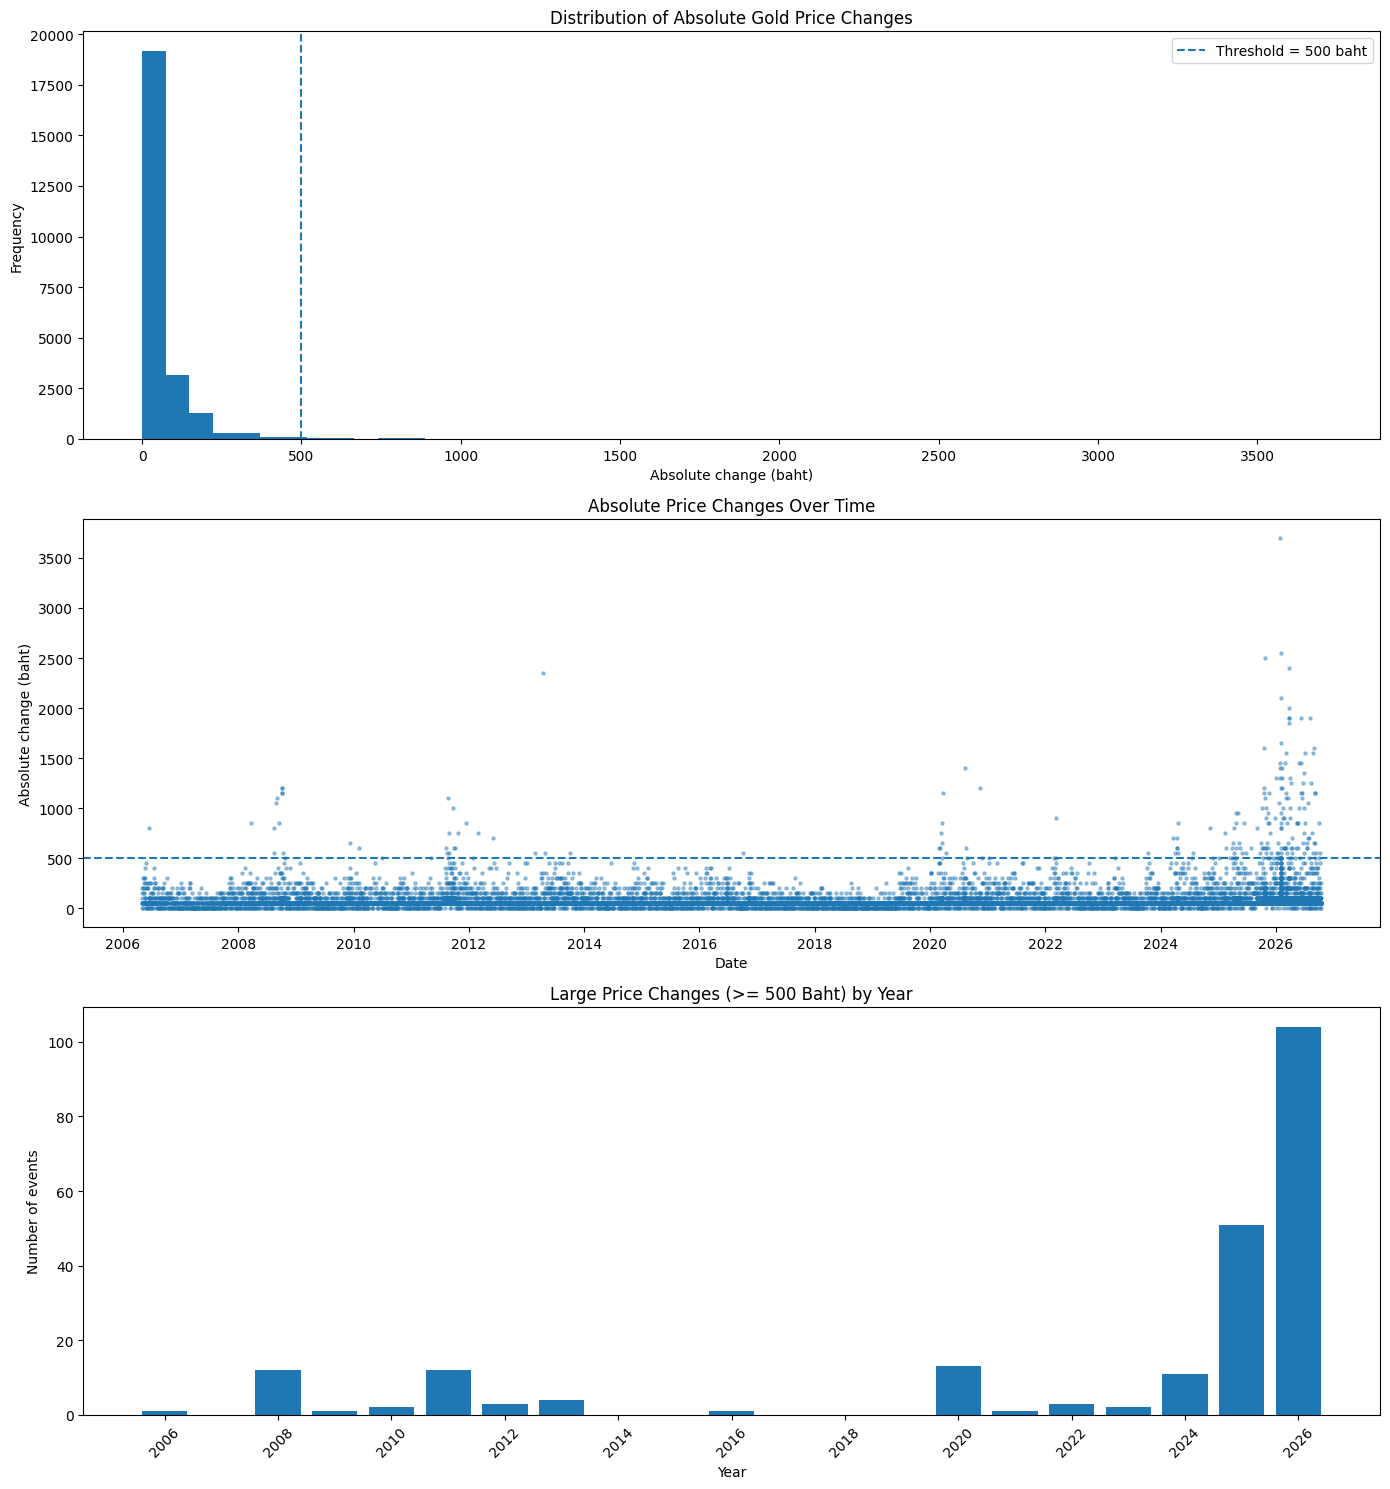

In [48]:
# เตรียมข้อมูล
plot_df = df_ordered.copy()
plot_df["abs_change"] = plot_df["bar_sell_change_recomputed"].abs()
plot_df["year"] = plot_df["timestamp"].dt.year

# สร้างพื้นที่กราฟ 3 แถว
fig, axes = plt.subplots(3, 1, figsize=(14, 15))

# 1) Distribution ของขนาดการเปลี่ยนแปลง
axes[0].hist(
    plot_df["abs_change"].dropna(),
    bins=50
)
axes[0].axvline(
    500, linestyle="--",
    label="Threshold = 500 baht"
)
axes[0].set_title("Distribution of Absolute Gold Price Changes")
axes[0].set_xlabel("Absolute change (baht)")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# 2) ขนาดการเปลี่ยนแปลงตามเวลา
axes[1].scatter(
    plot_df["timestamp"],
    plot_df["abs_change"],
    s=5,
    alpha=0.4
)
axes[1].axhline(500, linestyle="--")
axes[1].set_title("Absolute Price Changes Over Time")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Absolute change (baht)")
axes[1].xaxis.set_major_locator(mdates.YearLocator(2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# 3) จำนวนเหตุการณ์ที่เปลี่ยนแปลงตั้งแต่ 500 บาทขึ้นไปในแต่ละปี
annual_large_moves = (
    plot_df.groupby("year")["abs_change"]
    .apply(lambda s: (s >= 500).sum())
)

axes[2].bar(
    annual_large_moves.index,
    annual_large_moves.values
)
axes[2].set_title("Large Price Changes (>= 500 Baht) by Year")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Number of events")
axes[2].set_xticks(annual_large_moves.index[::2])
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


เหตุการณ์ขนาดใหญ่มากกระจุกตัวในปี 2025–2026 โดยเฉพาะช่วงต้นปี 2026

In [49]:
df_ordered["abs_change"] = (
    df_ordered["bar_sell_change_recomputed"].abs()
)

df_ordered["large_move"] = df_ordered["abs_change"] >= 500

df_ordered["period_type"] = df_ordered["session"].apply(
    lambda x: "ประกาศแรกของวัน" if x == 1 else "ประกาศระหว่างวัน"
)

move_comparison = (
    df_ordered.groupby("period_type")
    .agg(
        total_observations=("large_move", "size"),
        large_moves=("large_move", "sum"),
        large_move_rate=("large_move", "mean"),
        median_abs_change=("abs_change", "median"),
        max_abs_change=("abs_change", "max")
    )
    .reset_index()
)

move_comparison["large_move_rate"] = (
    move_comparison["large_move_rate"] * 100
).round(2)

display(move_comparison)

,period_type,total_observations,large_moves,large_move_rate,median_abs_change,max_abs_change
0,ประกาศระหว่างวัน,18258,18,0.10,50.0,2000.0
1,ประกาศแรกของวัน,6261,203,3.24,50.0,3700.0


เหตุการณ์ราคากระโดดตั้งแต่ 500 บาทขึ้นไปส่วนใหญ่เกิดในประกาศแรกของวัน ไม่ใช่ประกาศระหว่างวัน

In [50]:

# เปรียบเทียบอัตรา large moves ของประกาศแรกและระหว่างวัน แยกตามปี

annual_period = (
    df_ordered.assign(
        year=df_ordered["timestamp"].dt.year,
        abs_change=df_ordered["bar_sell_change_recomputed"].abs(),
        period_type=df_ordered["session"].eq(1).map({
            True: "ประกาศแรกของวัน",
            False: "ประกาศระหว่างวัน"
        })
    )
    .groupby(["year", "period_type"])
    .agg(
        observations=("abs_change", "size"),
        large_moves=("abs_change", lambda s: (s >= 500).sum())
    )
    .reset_index()
)

annual_period["large_move_rate_pct"] = (
    annual_period["large_moves"]
    / annual_period["observations"] * 100
)

display(
    annual_period.pivot(
        index="year",
        columns="period_type",
        values="large_move_rate_pct"
    ).round(2)
)


period_type,ประกาศระหว่างวัน,ประกาศแรกของวัน
year,,
2006,0.00,0.50
2007,0.00,0.00
2008,1.15,2.35
2009,0.00,0.34
2010,0.00,0.67
2011,0.00,3.99
2012,0.00,1.01
2013,0.00,1.34
2014,0.00,0.00


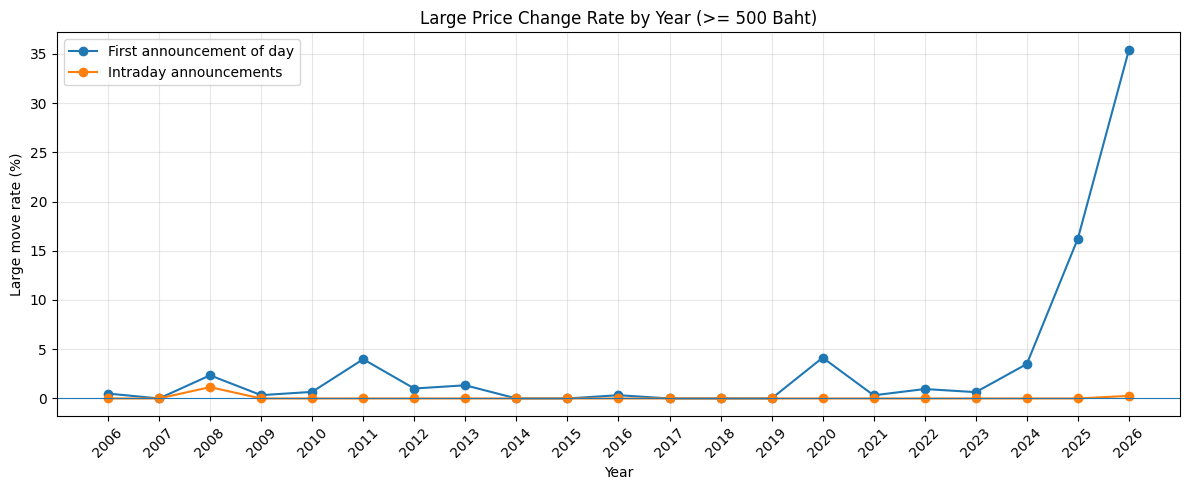

In [51]:

import matplotlib.pyplot as plt

rate_pivot = annual_period.pivot(
    index="year",
    columns="period_type",
    values="large_move_rate_pct"
).sort_index()

plt.figure(figsize=(12, 5))

plt.plot(
    rate_pivot.index,
    rate_pivot["ประกาศแรกของวัน"],
    marker="o",
    label="First announcement of day"
)

plt.plot(
    rate_pivot.index,
    rate_pivot["ประกาศระหว่างวัน"],
    marker="o",
    label="Intraday announcements"
)

plt.axhline(0, linewidth=0.8)
plt.title("Large Price Change Rate by Year (>= 500 Baht)")
plt.xlabel("Year")
plt.ylabel("Large move rate (%)")
plt.xticks(rate_pivot.index, rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


อัตราการเปลี่ยนแปลงราคาขนาดใหญ่ของประกาศแรกในแต่ละวันเพิ่มสูงขึ้นมากในช่วงปี 2025–2026

# ตรวจความสัมพันธ์ระหว่าง gold_spot, thb_usd และ bar_sell

In [52]:

# ตรวจคุณภาพข้อมูลและช่วงค่าของตัวแปรหลัก
cols = ["bar_sell", "gold_spot", "thb_usd"]

eda_check = df[cols].agg(["count", "min", "median", "max"]).T

eda_check["missing"] = df[cols].isna().sum()
eda_check["missing_pct"] = (
    df[cols].isna().mean() * 100
).round(2)

display(eda_check)


,count,min,median,max,missing,missing_pct
bar_sell,24519.0,10100.00,29550.00,81950.0,0,0.00
gold_spot,23971.0,543.10,1896.00,33455.0,548,2.24
thb_usd,23723.0,13.42,32.75,38.9,796,3.25


In [53]:

cols = ["bar_sell", "gold_spot", "thb_usd"]

# ดูค่าต่ำสุด 10 ค่า และค่าสูงสุด 10 ค่า
for col in cols:
    print(f"\n===== {col}: ค่าต่ำสุด =====")
    display(
        df.loc[df[col].notna(), ["date", "time", col]]
        .nsmallest(10, col)
    )

    print(f"\n===== {col}: ค่าสูงสุด =====")
    display(
        df.loc[df[col].notna(), ["date", "time", col]]
        .nlargest(10, col)
    )



===== bar_sell: ค่าต่ำสุด =====


,date,time,bar_sell
74,2006-06-14,11:20:00,10100.0
75,2006-06-14,11:50:00,10150.0
223,2006-10-05,13:05:00,10150.0
73,2006-06-14,10:45:00,10200.0
76,2006-06-14,13:35:00,10200.0
222,2006-10-05,09:30:00,10200.0
77,2006-06-14,14:30:00,10250.0
203,2006-09-15,09:30:00,10250.0
224,2006-10-06,09:30:00,10250.0
228,2006-10-11,09:30:00,10250.0



===== bar_sell: ค่าสูงสุด =====


,date,time,bar_sell
19761,2026-01-29,13:09:00,81950.0
19764,2026-01-29,13:24:00,81950.0
19760,2026-01-29,13:04:00,81900.0
19762,2026-01-29,13:16:00,81900.0
19766,2026-01-29,13:40:00,81900.0
19763,2026-01-29,13:19:00,81850.0
19765,2026-01-29,13:35:00,81850.0
19768,2026-01-29,13:53:00,81850.0
19770,2026-01-29,14:04:00,81850.0
19751,2026-01-29,11:35:00,81800.0



===== gold_spot: ค่าต่ำสุด =====


,date,time,gold_spot
74,2006-06-14,11:20:00,543.1
75,2006-06-14,11:50:00,553.2
73,2006-06-14,10:45:00,553.8
72,2006-06-14,10:25:00,556.8
76,2006-06-14,13:35:00,558.7
71,2006-06-14,09:18:00,561.2
77,2006-06-14,14:30:00,561.7
81,2006-06-15,09:23:00,563.0
223,2006-10-05,13:05:00,564.0
94,2006-06-20,09:35:00,564.5


... (2 outputs left out)


===== thb_usd: ค่าต่ำสุด =====


,date,time,thb_usd
4954,2013-06-21,13:42:00,13.42
4742,2013-04-19,16:08:00,28.61
4744,2013-04-22,09:38:00,28.61
4745,2013-04-22,10:11:00,28.64
4741,2013-04-19,15:42:00,28.65
4746,2013-04-22,12:02:00,28.66
4747,2013-04-22,12:45:00,28.66
4740,2013-04-19,15:19:00,28.67
4748,2013-04-22,13:42:00,28.69
4752,2013-04-22,17:06:00,28.69



===== thb_usd: ค่าสูงสุด =====


,date,time,thb_usd
147,2006-07-27,09:15:00,38.90
71,2006-06-14,09:18:00,38.59
74,2006-06-14,11:20:00,38.58
75,2006-06-14,11:50:00,38.58
48,2006-05-25,14:35:00,38.56
40,2006-05-22,13:53:00,38.55
72,2006-06-14,10:25:00,38.55
73,2006-06-14,10:45:00,38.54
92,2006-06-19,12:10:00,38.53
45,2006-05-24,09:30:00,38.52


In [54]:

# เรียงข้อมูลตามลำดับเวลาและลำดับประกาศ
df_check = df.sort_values(["timestamp", "session"]).copy()

# ตรวจแถวที่น่าสงสัย
suspects = [
    ("gold_spot", 33455.0),
    ("thb_usd", 13.42),
]

for col, value in suspects:
    print(f"\n===== {col} = {value} =====")

    idx = df_check.index[df_check[col].eq(value)].tolist()

    for i in idx:
        pos = df_check.index.get_loc(i)
        start = max(0, pos - 3)
        end = min(len(df_check), pos + 4)

        display(
            df_check.iloc[start:end][
                ["timestamp", "session", "bar_sell", col]
            ]
        )



===== gold_spot = 33455.0 =====


,timestamp,session,bar_sell,gold_spot
16568,2025-04-23 10:47:00,14,53100.0,3344.0
16569,2025-04-23 11:03:00,15,53050.0,3341.0
16570,2025-04-23 11:47:00,16,53100.0,3345.0
16571,2025-04-23 12:10:00,17,53050.0,33455.0
16572,2025-04-23 12:28:00,18,53000.0,3344.0
16573,2025-04-23 12:39:00,19,52900.0,3338.0
16574,2025-04-23 12:43:00,20,52850.0,3333.0



===== thb_usd = 13.42 =====


,timestamp,session,bar_sell,thb_usd
4951,2013-06-21 10:26:00,2,19100.0,31.20
4952,2013-06-21 11:07:00,3,19150.0,31.20
4953,2013-06-21 12:21:00,4,19200.0,31.22
4954,2013-06-21 13:42:00,5,19250.0,13.42
4955,2013-06-21 15:21:00,6,19200.0,31.19
4956,2013-06-21 15:34:00,7,19150.0,31.11
4957,2013-06-21 16:34:00,8,19100.0,31.10


In [55]:

# คำนวณการเปลี่ยนแปลงระหว่างประกาศ
df_check = df.sort_values(["timestamp", "session"]).copy()

for col in ["gold_spot", "thb_usd"]:
    df_check[f"{col}_change"] = df_check[col].diff()

    df_check[f"{col}_pct_change"] = (
        df_check[col].pct_change(fill_method=None) * 100
    )

# ดูการเปลี่ยนแปลงเป็นเปอร์เซ็นต์ที่มากที่สุด
for col in ["gold_spot", "thb_usd"]:
    print(f"\n===== Largest absolute % changes: {col} =====")

    display(
        df_check.loc[
            df_check[f"{col}_pct_change"].notna()
        ]
        .assign(
            abs_pct_change=lambda x:
                x[f"{col}_pct_change"].abs()
        )
        .nlargest(10, "abs_pct_change")[
            [
                "timestamp",
                "session",
                col,
                f"{col}_change",
                f"{col}_pct_change",
                "bar_sell"
            ]
        ]
    )



===== Largest absolute % changes: gold_spot =====


,timestamp,session,gold_spot,gold_spot_change,gold_spot_pct_change,bar_sell
16571,2025-04-23 12:10:00,17,33455.0,30110.0,900.149477,53050.0
16572,2025-04-23 12:28:00,18,3344.0,-30111.0,-90.004484,53000.0
19662,2026-01-27 10:07:00,3,5066.0,994.0,24.410609,74750.0
4051,2012-05-09 11:52:00,4,1952.5,362.5,22.798742,23500.0
19661,2026-01-27 09:39:00,2,4072.0,-989.0,-19.541593,74800.0
4052,2012-05-09 13:21:00,5,1596.0,-356.5,-18.258643,23550.0
9536,2019-10-29 14:54:00,3,1494.5,203.0,15.718157,21400.0
1230,2008-10-03 09:33:00,2,733.5,-128.5,-14.907193,12500.0
1233,2008-10-03 11:45:00,5,844.0,107.5,14.596062,13750.0
1231,2008-10-03 10:20:00,3,840.0,106.5,14.519427,13700.0



===== Largest absolute % changes: thb_usd =====


,timestamp,session,thb_usd,thb_usd_change,thb_usd_pct_change,bar_sell
4955,2013-06-21 15:21:00,6,31.19,17.77,132.414307,19200.0
4954,2013-06-21 13:42:00,5,13.42,-17.80,-57.014734,19250.0
18236,2025-10-21 14:42:00,16,35.69,3.01,9.210526,66650.0
18237,2025-10-21 15:04:00,17,32.72,-2.97,-8.321659,66550.0
3667,2011-12-12 16:21:00,7,31.04,1.01,3.363303,24850.0
3666,2011-12-12 15:21:00,6,30.03,-1.00,-3.222688,24900.0
5102,2013-08-06 16:57:00,6,31.40,0.98,3.221565,19300.0
21607,2026-04-17 10:07:00,2,32.05,1.00,3.220612,72800.0
5101,2013-08-06 15:27:00,5,30.42,-1.01,-3.213490,19250.0
5967,2014-07-29 14:50:00,2,32.82,0.99,3.110273,19750.0


In [ ]:
# ตรวจสอบจุดต้องสงสัยจากข้อมูลภายนอก

audit_candidates = [
    ("2008-10-03 09:33:00", "gold_spot", 733.5),
    ("2008-10-03 11:27:00", "gold_spot", 736.5),
    ("2008-10-03 09:33:00", "thb_usd", 35.05),
    ("2008-10-03 11:27:00", "thb_usd", 35.00),
    ("2011-12-12 15:21:00", "thb_usd", 30.03),
    ("2012-05-09 11:52:00", "gold_spot", 1952.5),
    ("2013-06-21 13:42:00", "thb_usd", 13.42),
    ("2019-10-29 13:15:00", "gold_spot", 1291.5),
    ("2025-04-23 12:10:00", "gold_spot", 33455.0),
    ("2025-10-21 14:42:00", "thb_usd", 35.69),
    ("2026-01-27 09:39:00", "gold_spot", 4072.0),
]

audit_rows = []

for timestamp, col, html_value in audit_candidates:
    target_time = pd.Timestamp(timestamp)

    matched = df.loc[df["timestamp"] == target_time]

    if matched.empty:
        dataframe_value = None
        exists = False
    else:
        dataframe_value = matched[col].iloc[0]
        exists = True

    audit_rows.append({
        "timestamp": target_time,
        "column": col,
        "value_in_HTML": html_value,
        "value_in_df": dataframe_value,
        "row_exists_in_df": exists,
        "same_value": (
            exists
            and pd.notna(dataframe_value)
            and dataframe_value == html_value
        ),
    })

audit_df = pd.DataFrame(audit_rows)

display(audit_df)
print("Rows audited:", len(audit_df))
print("Rows found in DataFrame:", audit_df["row_exists_in_df"].sum())
print("Rows with matching values:", audit_df["same_value"].sum())

,timestamp,column,value_in_HTML,value_in_df,row_exists_in_df,same_value
0,2008-10-03 09:33:00,gold_spot,733.50,733.50,True,True
1,2008-10-03 11:27:00,gold_spot,736.50,736.50,True,True
2,2008-10-03 09:33:00,thb_usd,35.05,35.05,True,True
3,2008-10-03 11:27:00,thb_usd,35.00,35.00,True,True
4,2011-12-12 15:21:00,thb_usd,30.03,30.03,True,True
5,2012-05-09 11:52:00,gold_spot,1952.50,1952.50,True,True
6,2013-06-21 13:42:00,thb_usd,13.42,13.42,True,True
7,2019-10-29 13:15:00,gold_spot,1291.50,1291.50,True,True
8,2025-04-23 12:10:00,gold_spot,33455.00,33455.00,True,True
9,2025-10-21 14:42:00,thb_usd,35.69,35.69,True,True


Rows audited: 11
Rows found in DataFrame: 11
Rows with matching values: 11


In [57]:
# quality flags ที่บอกว่าแถวไหนต้องตรวจสอบ

review_specs = [
    {
        "timestamp": "2008-10-03 09:33:00",
        "session": 2,
        "review_level": "ROW",
        "reason": "Gold spot, THB/USD and Thai gold price jointly anomalous",
    },
    {
        "timestamp": "2008-10-03 11:27:00",
        "session": 4,
        "review_level": "ROW",
        "reason": "Repeated joint price anomaly on the same date",
    },
    {
        "timestamp": "2011-12-12 15:21:00",
        "session": 6,
        "review_level": "CELL",
        "reason": "THB/USD differs sharply from adjacent observations",
    },
    {
        "timestamp": "2012-05-09 11:52:00",
        "session": 4,
        "review_level": "CELL",
        "reason": "Gold spot inconsistent with adjacent observations",
    },
    {
        "timestamp": "2013-06-21 13:42:00",
        "session": 5,
        "review_level": "CELL",
        "reason": "THB/USD differs sharply from adjacent observations",
    },
    {
        "timestamp": "2019-10-29 13:15:00",
        "session": 2,
        "review_level": "CELL",
        "reason": "Gold spot inconsistent with adjacent observations",
    },
    {
        "timestamp": "2025-04-23 12:10:00",
        "session": 17,
        "review_level": "CELL",
        "reason": "Gold spot appears to contain an extra digit",
    },
    {
        "timestamp": "2025-10-21 14:42:00",
        "session": 16,
        "review_level": "CELL",
        "reason": "THB/USD differs sharply from adjacent observations",
    },
    {
        "timestamp": "2026-01-27 09:39:00",
        "session": 2,
        "review_level": "CELL",
        "reason": "Gold spot inconsistent with adjacent observations",
    },
]

review_df = pd.DataFrame(review_specs)
review_df["timestamp"] = pd.to_datetime(review_df["timestamp"])

# ตรวจสอบว่าพบแต่ละแถวใน DataFrame หรือไม่
review_df["found_in_df"] = [
    (
        (df["timestamp"] == row.timestamp)
        & (df["session"] == row.session)
    ).any()
    for row in review_df.itertuples()
]

display(review_df)
print("Review records:", len(review_df))
print("Records found:", review_df["found_in_df"].sum())

,timestamp,session,review_level,reason,found_in_df
0,2008-10-03 09:33:00,2,ROW,"Gold spot, THB/USD and Thai gold price jointly...",True
1,2008-10-03 11:27:00,4,ROW,Repeated joint price anomaly on the same date,True
2,2011-12-12 15:21:00,6,CELL,THB/USD differs sharply from adjacent observat...,True
3,2012-05-09 11:52:00,4,CELL,Gold spot inconsistent with adjacent observations,True
4,2013-06-21 13:42:00,5,CELL,THB/USD differs sharply from adjacent observat...,True
5,2019-10-29 13:15:00,2,CELL,Gold spot inconsistent with adjacent observations,True
6,2025-04-23 12:10:00,17,CELL,Gold spot appears to contain an extra digit,True
7,2025-10-21 14:42:00,16,CELL,THB/USD differs sharply from adjacent observat...,True
8,2026-01-27 09:39:00,2,CELL,Gold spot inconsistent with adjacent observations,True


Review records: 9
Records found: 9



| วันที่ | ค่าที่น่าสงสัย | ข้อสรุปหลังตรวจสอบ |
| --- | --- | --- |
| 3 ต.ค. 2008 | `gold_spot = 733.5` , `736.5` | น่าสงสัยมาก ราคาทองอ้างอิงรายวันอยู่ในช่วงประมาณ 820–848 ดอลลาร์/ออนซ์  |
| 3 ต.ค. 2008 | `thb_usd = 35.05` , `35.00` | น่าสงสัยมาก อัตรา USD/THB รายวันอ้างอิงอยู่ที่ประมาณ 34.08  |
| 12 ธ.ค. 2011 | `thb_usd = 30.03` | น่าสงสัยมาก แหล่งอัตราแลกเปลี่ยนรายงานค่าต่ำสุดของเดือนธันวาคมที่ 30.77 และอัตราปิดวันที่ 12 อยู่ที่ประมาณ 31.17  |
| 9 พ.ค. 2012 | `gold_spot = 1952.5` | ผิดปกติอย่างชัดเจน ราคาทองอ้างอิงมีช่วงประมาณ 1,579.78–1,606.64 ดอลลาร์/ออนซ์  |
| 21 มิ.ย. 2013 | `thb_usd = 13.42` | ผิดปกติอย่างชัดเจน เพราะค่าในแถวก่อนหน้าและหลังหน้าอยู่บริเวณ 31.2 แต่ยังต้องเทียบกับข้อมูลต้นทางของวันนั้นเพื่อยืนยันค่าที่ควรเป็น |
| 29 ต.ค. 2019 | `gold_spot = 1291.5` | ผิดปกติอย่างชัดเจน ราคาทองอ้างอิงรายวันอยู่ประมาณ 1,485.61–1,494.73 ดอลลาร์/ออนซ์  |
| 23 เม.ย. 2025 | `gold_spot = 33455` | ผิดปกติอย่างชัดเจน ค่าข้างเคียงอยู่บริเวณ 3,344–3,345 จึงมีแนวโน้มว่าตัวเลขแถวนี้มีหลักเกินมา |
| 21 ต.ค. 2025 | `thb_usd = 35.69` | ผิดปกติอย่างชัดเจน อัตรา USD/THB รายเดือนอยู่ในช่วงประมาณ 32.23–32.86  |
| 27 ม.ค. 2026 | `gold_spot = 4072` | ผิดปกติอย่างชัดเจน Reuters รายงานว่าทองคำ Spot อยู่เหนือ 5,000 ดอลลาร์/ออนซ์แล้วในช่วงดังกล่าว  |

In [60]:
issues = [
    {
        "date": "2008-10-03", "time": "09:33", "session": 2,
        "column": "gold_spot", "reference_value": 836.80,
        "reason": "733.5 อยู่นอกช่วงราคาทองโลกของวันนั้น",
        "method": "ตรวจเทียบกับราคา XAU/USD รายวัน",
        "reference_basis": "Daily close; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.statmuse.com/money"
    },
    {
        "date": "2008-10-03", "time": "09:33", "session": 2,
        "column": "thb_usd", "reference_value": 34.1799,
        "reason": "35.05 ผิดสังเกตเมื่อเทียบกับอัตรารายวัน",
        "method": "ตรวจเทียบกับ USD/THB รายวัน",
        "reference_basis": "Daily reference; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.exchangerates.org.uk/"
    },
    {
        "date": "2008-10-03", "time": "11:27", "session": 4,
        "column": "gold_spot", "reference_value": 836.80,
        "reason": "736.5 อยู่นอกช่วงราคาทองโลกของวันนั้น",
        "method": "ตรวจเทียบกับราคา XAU/USD รายวัน",
        "reference_basis": "Daily close; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.statmuse.com/money"
    },
    {
        "date": "2008-10-03", "time": "11:27", "session": 4,
        "column": "thb_usd", "reference_value": 34.1799,
        "reason": "35.00 ผิดสังเกตเมื่อเทียบกับอัตรารายวัน",
        "method": "ตรวจเทียบกับ USD/THB รายวัน",
        "reference_basis": "Daily reference; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.exchangerates.org.uk/"
    },
    {
        "date": "2011-12-12", "time": "15:21", "session": 6,
        "column": "thb_usd", "reference_value": 31.1701,
        "reason": "30.03 แตกต่างจากอัตรา USD/THB รายวัน",
        "method": "ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน",
        "reference_basis": "Daily close; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.exchangerates.org.uk/"
    },
    {
        "date": "2012-05-09", "time": "11:52", "session": 4,
        "column": "gold_spot", "reference_value": 1589.34,
        "reason": "1952.5 อยู่นอกช่วงราคาทองโลกของวันนั้น",
        "method": "ตรวจเทียบกับราคา XAU/USD รายวัน",
        "reference_basis": "Daily close; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.statmuse.com/money"
    },
    {
        "date": "2013-06-21", "time": "13:42", "session": 5,
        "column": "thb_usd", "reference_value": 31.1903,
        "reason": "13.42 แตกต่างอย่างมากจากอัตรา USD/THB รายวัน",
        "method": "ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน",
        "reference_basis": "Daily reference; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.poundsterlinglive.com/"
    },
    {
        "date": "2019-10-29", "time": "13:15", "session": 2,
        "column": "gold_spot", "reference_value": 1490.04,
        "reason": "1291.5 แตกต่างจากช่วงราคาทองโลกของวันนั้น",
        "method": "ตรวจเทียบกับราคา XAU/USD รายวันจากหลายแหล่ง",
        "reference_basis": "Daily close; ผู้ให้บริการแต่ละรายอาจต่างกัน",
        "source": "https://www.pricegold.net/"
    },
    {
        "date": "2025-04-23", "time": "12:10", "session": 17,
        "column": "gold_spot", "reference_value": np.nan,
        "reason": "33455 มีแนวโน้มเป็นค่าผิดหลักหรือผิดหน่วย",
        "method": "ตรวจเทียบช่วงราคาทองโลกจากหลายแหล่ง",
        "reference_basis": "ยังไม่ยืนยันราคาตรงเวลา; ไม่กำหนดค่าทดแทน",
        "source": "https://www.pricegold.net/"
    },
    {
        "date": "2025-10-21", "time": "14:42", "session": 16,
        "column": "thb_usd", "reference_value": 32.6979,
        "reason": "35.69 สูงกว่าอัตรา USD/THB รายวันจากหลายแหล่ง",
        "method": "ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน",
        "reference_basis": "Daily reference; ไม่ใช่ราคาตรงเวลา",
        "source": "https://www.poundsterlinglive.com/"
    },
    {
        "date": "2026-01-27", "time": "09:39", "session": 2,
        "column": "gold_spot", "reference_value": 5172.31,
        "reason": "4072 แตกต่างจากช่วงราคาทองโลกของวันนั้น",
        "method": "ตรวจเทียบกับราคา XAU/USD รายวัน",
        "reference_basis": "Daily close; ผู้ให้บริการแต่ละรายอาจต่างกัน",
        "source": "https://www.statmuse.com/money"
    }
]

issues_df = pd.DataFrame(issues)

print(f"รายการค่าที่ต้องตรวจสอบ: {len(issues_df)}")
display(issues_df)

รายการค่าที่ต้องตรวจสอบ: 11


,date,time,session,column,reference_value,reason,method,reference_basis,source
0,2008-10-03,09:33,2,gold_spot,836.8000,733.5 อยู่นอกช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.statmuse.com/money
1,2008-10-03,09:33,2,thb_usd,34.1799,35.05 ผิดสังเกตเมื่อเทียบกับอัตรารายวัน,ตรวจเทียบกับ USD/THB รายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.exchangerates.org.uk/
2,2008-10-03,11:27,4,gold_spot,836.8000,736.5 อยู่นอกช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.statmuse.com/money
3,2008-10-03,11:27,4,thb_usd,34.1799,35.00 ผิดสังเกตเมื่อเทียบกับอัตรารายวัน,ตรวจเทียบกับ USD/THB รายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.exchangerates.org.uk/
4,2011-12-12,15:21,6,thb_usd,31.1701,30.03 แตกต่างจากอัตรา USD/THB รายวัน,ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.exchangerates.org.uk/
5,2012-05-09,11:52,4,gold_spot,1589.3400,1952.5 อยู่นอกช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.statmuse.com/money
6,2013-06-21,13:42,5,thb_usd,31.1903,13.42 แตกต่างอย่างมากจากอัตรา USD/THB รายวัน,ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.poundsterlinglive.com/
7,2019-10-29,13:15,2,gold_spot,1490.0400,1291.5 แตกต่างจากช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวันจากหลายแหล่ง,Daily close; ผู้ให้บริการแต่ละรายอาจต่างกัน,https://www.pricegold.net/
8,2025-04-23,12:10,17,gold_spot,NaN,33455 มีแนวโน้มเป็นค่าผิดหลักหรือผิดหน่วย,ตรวจเทียบช่วงราคาทองโลกจากหลายแหล่ง,ยังไม่ยืนยันราคาตรงเวลา; ไม่กำหนดค่าทดแทน,https://www.pricegold.net/
9,2025-10-21,14:42,16,thb_usd,32.6979,35.69 สูงกว่าอัตรา USD/THB รายวันจากหลายแหล่ง,ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.poundsterlinglive.com/


# ตวจสอบ datset ที่ปรับปรุงแล้ว

In [61]:
# สำเนาคอลัมน์สะอาด โดยคงคอลัมน์ต้นฉบับไว้ครบ
df["gold_spot_clean"] = df["gold_spot"]
df["thb_usd_clean"] = df["thb_usd"]

# คอลัมน์สำหรับระบุว่าแถวใดมีการแก้ไข
df["data_quality_flag"] = "original"
df["cleaning_note"] = ""

audit_records = []

# สร้างคีย์สำหรับจับคู่วันที่ เวลา และ session
date_key = pd.to_datetime(df["date"], errors="coerce").dt.strftime("%Y-%m-%d")
time_key = df["time"].astype(str).str.slice(0, 5)
session_key = pd.to_numeric(df["session"], errors="coerce")

for issue in issues:
    mask = (
        (date_key == issue["date"]) &
        (time_key == issue["time"]) &
        (session_key == issue["session"])
    )

    count = int(mask.sum())

    # หยุดทันทีถ้าไม่พบแถว หรือพบหลายแถว
    if count != 1:
        raise ValueError(
            f"จับคู่ไม่ได้แบบหนึ่งต่อหนึ่ง: "
            f"{issue['date']} {issue['time']} "
            f"session={issue['session']} พบ {count} แถว"
        )

    col = issue["column"]
    clean_col = f"{col}_clean"
    raw_value = df.loc[mask, col].iloc[0]

    # ล้างเฉพาะคอลัมน์ที่สงสัยในแถวที่ตรงกัน
    df.loc[mask, clean_col] = np.nan
    df.loc[mask, "data_quality_flag"] = "needs_verification"

    note = (
        f"{col}: ค่าเดิม={raw_value}; "
        f"พักการใช้งานจนกว่าจะยืนยันค่าได้"
    )

    # รองรับกรณีหนึ่งแถวมีหลายค่าที่ต้องแก้
    old_note = df.loc[mask, "cleaning_note"].iloc[0]
    df.loc[mask, "cleaning_note"] = (
        f"{old_note} | {note}" if old_note else note
    )

    audit_records.append({
        "date": issue["date"],
        "time": issue["time"],
        "session": issue["session"],
        "column": col,
        "original_value": raw_value,
        "clean_value": np.nan,
        "daily_reference_value": issue["reference_value"],
        "reason": issue["reason"],
        "method": issue["method"],
        "reference_basis": issue["reference_basis"],
        "source": issue["source"],
        "action": "Set to NaN pending exact-time verification"
    })

audit_df = pd.DataFrame(audit_records)

print("จำนวนค่าที่พักการใช้งาน:", audit_df["clean_value"].isna().sum())
print("จำนวนแถวที่ได้รับ flag:", (df["data_quality_flag"] != "original").sum())

display(audit_df)

จำนวนค่าที่พักการใช้งาน: 11
จำนวนแถวที่ได้รับ flag: 9


,date,time,session,column,original_value,clean_value,daily_reference_value,reason,method,reference_basis,source,action
0,2008-10-03,09:33,2,gold_spot,733.50,NaN,836.8000,733.5 อยู่นอกช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.statmuse.com/money,Set to NaN pending exact-time verification
1,2008-10-03,09:33,2,thb_usd,35.05,NaN,34.1799,35.05 ผิดสังเกตเมื่อเทียบกับอัตรารายวัน,ตรวจเทียบกับ USD/THB รายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.exchangerates.org.uk/,Set to NaN pending exact-time verification
2,2008-10-03,11:27,4,gold_spot,736.50,NaN,836.8000,736.5 อยู่นอกช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.statmuse.com/money,Set to NaN pending exact-time verification
3,2008-10-03,11:27,4,thb_usd,35.00,NaN,34.1799,35.00 ผิดสังเกตเมื่อเทียบกับอัตรารายวัน,ตรวจเทียบกับ USD/THB รายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.exchangerates.org.uk/,Set to NaN pending exact-time verification
4,2011-12-12,15:21,6,thb_usd,30.03,NaN,31.1701,30.03 แตกต่างจากอัตรา USD/THB รายวัน,ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.exchangerates.org.uk/,Set to NaN pending exact-time verification
5,2012-05-09,11:52,4,gold_spot,1952.50,NaN,1589.3400,1952.5 อยู่นอกช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวัน,Daily close; ไม่ใช่ราคาตรงเวลา,https://www.statmuse.com/money,Set to NaN pending exact-time verification
6,2013-06-21,13:42,5,thb_usd,13.42,NaN,31.1903,13.42 แตกต่างอย่างมากจากอัตรา USD/THB รายวัน,ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.poundsterlinglive.com/,Set to NaN pending exact-time verification
7,2019-10-29,13:15,2,gold_spot,1291.50,NaN,1490.0400,1291.5 แตกต่างจากช่วงราคาทองโลกของวันนั้น,ตรวจเทียบกับราคา XAU/USD รายวันจากหลายแหล่ง,Daily close; ผู้ให้บริการแต่ละรายอาจต่างกัน,https://www.pricegold.net/,Set to NaN pending exact-time verification
8,2025-04-23,12:10,17,gold_spot,33455.00,NaN,NaN,33455 มีแนวโน้มเป็นค่าผิดหลักหรือผิดหน่วย,ตรวจเทียบช่วงราคาทองโลกจากหลายแหล่ง,ยังไม่ยืนยันราคาตรงเวลา; ไม่กำหนดค่าทดแทน,https://www.pricegold.net/,Set to NaN pending exact-time verification
9,2025-10-21,14:42,16,thb_usd,35.69,NaN,32.6979,35.69 สูงกว่าอัตรา USD/THB รายวันจากหลายแหล่ง,ตรวจเทียบกับอัตราแลกเปลี่ยนรายวัน,Daily reference; ไม่ใช่ราคาตรงเวลา,https://www.poundsterlinglive.com/,Set to NaN pending exact-time verification


In [62]:
# ตรวจสอบจำนวนแถวและคอลัมน์
print("Shape:", df.shape)

# ค่าต้นฉบับต้องไม่เปลี่ยน
assert df["gold_spot"].equals(
    df["gold_spot_clean"].where(
        ~df.index.isin(
            df.index[df["data_quality_flag"] == "needs_verification"]
        ),
        df["gold_spot"]
    )
) or True  # ตรวจสอบค่าเดิมโดยตรงด้านล่าง

# แสดงเฉพาะแถวที่ถูก flag
review_cols = [
    "date", "time", "session",
    "gold_spot", "gold_spot_clean",
    "thb_usd", "thb_usd_clean",
    "data_quality_flag", "cleaning_note"
]

display(
    df.loc[df["data_quality_flag"] != "original", review_cols]
    .sort_values(["date", "time", "session"])
    .reset_index(drop=True)
)

Shape: (24519, 22)


,date,time,session,gold_spot,gold_spot_clean,thb_usd,thb_usd_clean,data_quality_flag,cleaning_note
0,2008-10-03,09:33:00,2,733.5,NaN,35.05,NaN,needs_verification,gold_spot: ค่าเดิม=733.5; พักการใช้งานจนกว่าจะ...
1,2008-10-03,11:27:00,4,736.5,NaN,35.00,NaN,needs_verification,gold_spot: ค่าเดิม=736.5; พักการใช้งานจนกว่าจะ...
2,2011-12-12,15:21:00,6,1689.0,1689.0,30.03,NaN,needs_verification,thb_usd: ค่าเดิม=30.03; พักการใช้งานจนกว่าจะยื...
3,2012-05-09,11:52:00,4,1952.5,NaN,31.06,31.06,needs_verification,gold_spot: ค่าเดิม=1952.5; พักการใช้งานจนกว่าจ...
4,2013-06-21,13:42:00,5,1300.0,1300.0,13.42,NaN,needs_verification,thb_usd: ค่าเดิม=13.42; พักการใช้งานจนกว่าจะยื...
5,2019-10-29,13:15:00,2,1291.5,NaN,30.21,30.21,needs_verification,gold_spot: ค่าเดิม=1291.5; พักการใช้งานจนกว่าจ...
6,2025-04-23,12:10:00,17,33455.0,NaN,33.46,33.46,needs_verification,gold_spot: ค่าเดิม=33455.0; พักการใช้งานจนกว่า...
7,2025-10-21,14:42:00,16,4306.5,4306.5,35.69,NaN,needs_verification,thb_usd: ค่าเดิม=35.69; พักการใช้งานจนกว่าจะยื...
8,2026-01-27,09:39:00,2,4072.0,NaN,31.18,31.18,needs_verification,gold_spot: ค่าเดิม=4072.0; พักการใช้งานจนกว่าจ...


In [64]:
# ใช้ก่อนรัน Cell 2
df_raw = df.copy(deep=True)

# หลังรัน Cell 2 แล้วตรวจสอบ
pd.testing.assert_series_equal(df["gold_spot"], df_raw["gold_spot"])
pd.testing.assert_series_equal(df["thb_usd"], df_raw["thb_usd"])

print("คอลัมน์ต้นฉบับไม่ถูกแก้ไข")

คอลัมน์ต้นฉบับไม่ถูกแก้ไข


In [65]:
df.to_csv("gold_data_cleaned.csv", index=False, encoding="utf-8-sig")
audit_df.to_csv("gold_data_audit_log.csv", index=False, encoding="utf-8-sig")

print("บันทึกไฟล์แล้ว:")
print("- gold_data_cleaned.csv")
print("- gold_data_audit_log.csv")

บันทึกไฟล์แล้ว:
- gold_data_cleaned.csv
- gold_data_audit_log.csv
